In [66]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [67]:
df = pd.read_csv('placement.csv')

In [68]:
df.head()

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0


<Axes: xlabel='placement_exam_marks', ylabel='Count'>

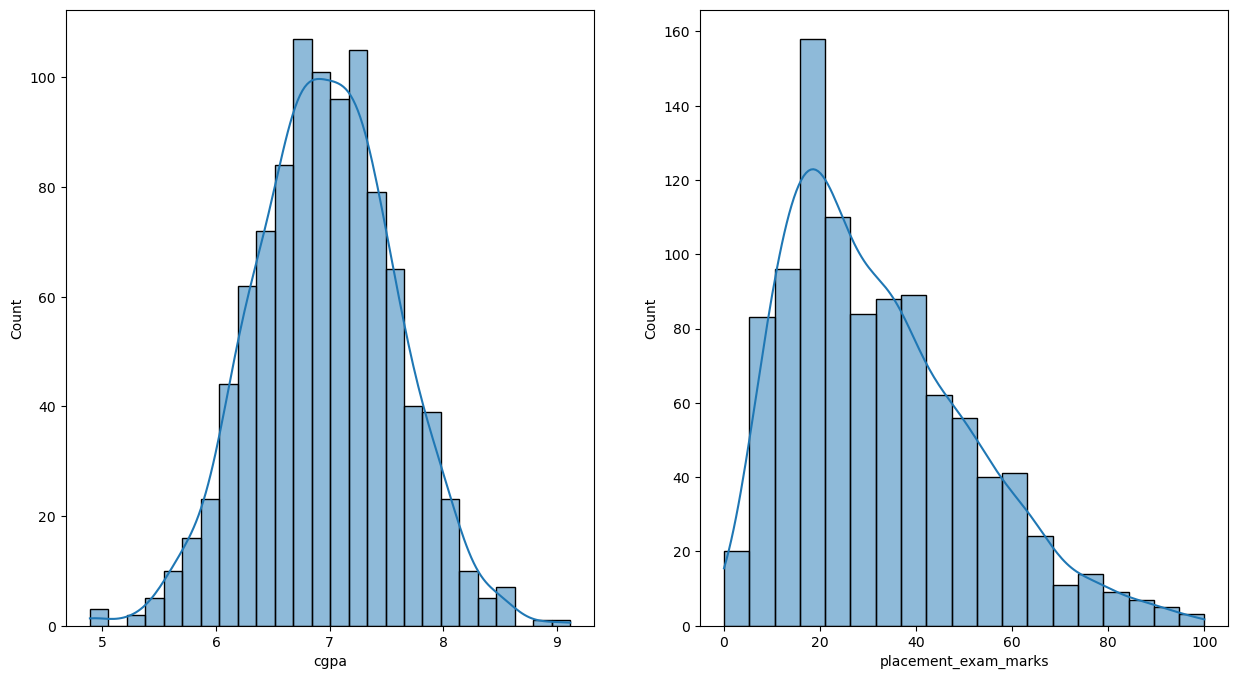

In [69]:
plt.figure(figsize=(15,8))
plt.subplot(121)
sns.histplot(df['cgpa'],kde=True)

plt.subplot(122)
sns.histplot(df['placement_exam_marks'],kde=True)

In [70]:
df['cgpa'].describe()

count    1000.000000
mean        6.961240
std         0.615898
min         4.890000
25%         6.550000
50%         6.960000
75%         7.370000
max         9.120000
Name: cgpa, dtype: float64

In [71]:
print("Mean ",df['cgpa'].mean())
print("SD ",df['cgpa'].std())
print("Mim value ",df['cgpa'].min())
print("Max value ",df['cgpa'].max())

Mean  6.96124
SD  0.6158978751323894
Mim value  4.89
Max value  9.12


In [72]:
#  finding the boundries   mean-3sd is min       and        mean+3sd  is max
print("Highest allowed ",df['cgpa'].mean()+3*(df['cgpa'].std()))
print("Lowest allowed ",df['cgpa'].mean()-3*(df['cgpa'].std()))


Highest allowed  8.808933625397168
Lowest allowed  5.113546374602832


In [73]:
#  finding the outlier

df[(df['cgpa']>8.808933625397168) | (df['cgpa']<5.113546374602832)]

,cgpa,placement_exam_marks,placed
485,4.92,44.0,1
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
999,4.90,10.0,1


In [74]:
#  trimming
new_df=df[(df['cgpa']<8.808933625397168) & (df['cgpa']>5.113546374602832)]
new_df

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0
...,...,...,...
991,7.04,57.0,0
992,6.26,12.0,0
993,6.73,21.0,1
994,6.48,63.0,0


aproach 2 is by claculation z_score

In [75]:
df['Z_score']=(df['cgpa']-df['cgpa'].mean())/df['cgpa'].std()

In [76]:
df.head()

,cgpa,placement_exam_marks,placed,Z_score
0,7.19,26.0,1,0.371425
1,7.46,38.0,1,0.809810
2,7.54,40.0,1,0.939701
3,6.42,8.0,1,-0.878782
4,7.23,17.0,0,0.436371


In [77]:
df[df['Z_score']>3]

,cgpa,placement_exam_marks,placed,Z_score
995,8.87,44.0,1,3.099150
996,9.12,65.0,1,3.505062


In [78]:
df[df['Z_score']<-3]

,cgpa,placement_exam_marks,placed,Z_score
485,4.92,44.0,1,-3.314251
997,4.89,34.0,0,-3.362960
999,4.90,10.0,1,-3.346724


In [79]:
df[(df['Z_score']>3) | (df['Z_score']<-3)]

,cgpa,placement_exam_marks,placed,Z_score
485,4.92,44.0,1,-3.314251
995,8.87,44.0,1,3.099150
996,9.12,65.0,1,3.505062
997,4.89,34.0,0,-3.362960
999,4.90,10.0,1,-3.346724


In [80]:
#  triming
new_df2 = df[(df['Z_score']<3) & (df['Z_score']>-3)]

In [81]:
new_df2

,cgpa,placement_exam_marks,placed,Z_score
0,7.19,26.0,1,0.371425
1,7.46,38.0,1,0.809810
2,7.54,40.0,1,0.939701
3,6.42,8.0,1,-0.878782
4,7.23,17.0,0,0.436371
...,...,...,...,...
991,7.04,57.0,0,0.127878
992,6.26,12.0,0,-1.138565
993,6.73,21.0,1,-0.375452
994,6.48,63.0,0,-0.781363


# Capping

In [82]:
upper_limit=(df['cgpa'].mean()+3*df['cgpa'].std())
lower_limit=(df['cgpa'].mean()-3*df['cgpa'].std())

in np.where we pass three things np.where(x,y,z)   where x is a condition, y is what to do if the condition is true and z is the else

In [83]:
df['cgpa']=np.where(df['cgpa']>upper_limit,upper_limit,np.where(df['cgpa']<lower_limit,lower_limit,df['cgpa']))

In [84]:
df.shape

(1000, 4)

In [85]:
df['cgpa'].describe()

count    1000.000000
mean        6.961499
std         0.612688
min         5.113546
25%         6.550000
50%         6.960000
75%         7.370000
max         8.808934
Name: cgpa, dtype: float64